<a href="https://colab.research.google.com/github/MrTu286/Tuan4_TH_AI/blob/main/Tuan4_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Đặt random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Tải dữ liệu Fashion-MNIST
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# 3. Tách Training (50.000) / Validation (10.000) / Test (10.000)
VAL_SIZE = 10_000
X_val, y_val = X_train_full[-VAL_SIZE:], y_train_full[-VAL_SIZE:]
X_train, y_train = X_train_full[:-VAL_SIZE], y_train_full[:-VAL_SIZE]

# 4. Chuẩn hóa pixel về [0, 1]
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 5. Tạo pipeline tf.data với batch size mặc định 64
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"Sẵn sàng dữ liệu -> Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Sẵn sàng dữ liệu -> Train: (50000, 28, 28), Val: (10000, 28, 28), Test: (10000, 28, 28)


In [2]:
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

def build_mlp(hidden_units):
    layers = [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten()
    ]
    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    return tf.keras.Sequential(layers)

architectures = {
    "1 hidden layer (256)": [256],
    "2 hidden layers (256-128)": [256, 128],
    "3 hidden layers (256-128-64)": [256, 128, 64]
}

results_b1 = []
histories_b1 = {}

for name, units in architectures.items():
    # Reset session & seed để các lần thử độc lập và tái lập được
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = build_mlp(units)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    print(f"\n>>> Đang huấn luyện: {name} ...")
    start_time = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.perf_counter() - start_time

    # Lấy chỉ số tại best epoch (theo val_loss nhỏ nhất)
    best_idx = int(np.argmin(history.history["val_loss"]))
    best_epoch = best_idx + 1
    best_val_acc = history.history["val_accuracy"][best_idx]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    histories_b1[name] = history.history
    results_b1.append({
        "Kiến trúc": name,
        "Số params": f"{model.count_params():,}",
        "Epochs chạy": len(history.history["loss"]),
        "Best epoch": best_epoch,
        "Train time (s)": round(train_time, 2),
        "Val accuracy": round(best_val_acc, 4),
        "Test accuracy": round(test_acc, 4)
    })

df_b1 = pd.DataFrame(results_b1)
print("\n=== BẢNG SO SÁNH BÀI 1: THAY ĐỔI KIẾN TRÚC ===")
print(df_b1.to_string(index=False, justify="left"))


>>> Đang huấn luyện: 1 hidden layer (256) ...

>>> Đang huấn luyện: 2 hidden layers (256-128) ...

>>> Đang huấn luyện: 3 hidden layers (256-128-64) ...

=== BẢNG SO SÁNH BÀI 1: THAY ĐỔI KIẾN TRÚC ===
Kiến trúc                    Số params  Epochs chạy  Best epoch  Train time (s)  Val accuracy  Test accuracy
        1 hidden layer (256) 203,530   12            9          31.37           0.8839        0.8818        
   2 hidden layers (256-128) 235,146   11            8          28.10           0.8902        0.8863        
3 hidden layers (256-128-64) 242,762   13           10          34.31           0.8892        0.8833        


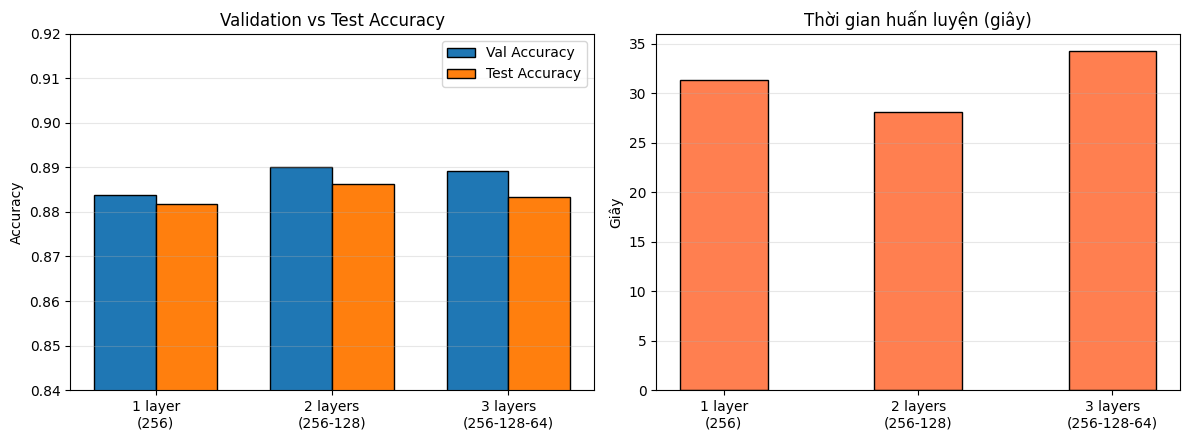

In [3]:
import matplotlib.pyplot as plt

labels = ["1 layer\n(256)", "2 layers\n(256-128)", "3 layers\n(256-128-64)"]
x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: Validation vs Test Accuracy
axes[0].bar(x - width/2, df_b1["Val accuracy"], width, label="Val Accuracy", edgecolor="black")
axes[0].bar(x + width/2, df_b1["Test accuracy"], width, label="Test Accuracy", edgecolor="black")
axes[0].set_title("Validation vs Test Accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.84, 0.92)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Biểu đồ 2: Thời gian huấn luyện
axes[1].bar(x, df_b1["Train time (s)"], width=0.45, color="coral", edgecolor="black")
axes[1].set_title("Thời gian huấn luyện (giây)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Giây")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
learning_rates = [1e-2, 1e-3, 1e-4]

results_b2 = []
histories_b2 = {}

for lr in learning_rates:
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    lr_label = f"{lr:.0e}"
    print(f"\n>>> Đang huấn luyện với learning_rate = {lr_label} ...")
    start_time = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.perf_counter() - start_time

    best_idx = int(np.argmin(history.history["val_loss"]))
    best_epoch = best_idx + 1
    best_val_loss = history.history["val_loss"][best_idx]
    best_val_acc = history.history["val_accuracy"][best_idx]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    histories_b2[lr_label] = history.history
    results_b2.append({
        "Learning rate": lr_label,
        "Epochs chạy": len(history.history["loss"]),
        "Best epoch": best_epoch,
        "Train time (s)": round(train_time, 2),
        "Val loss": round(best_val_loss, 4),
        "Val accuracy": round(best_val_acc, 4),
        "Test accuracy": round(test_acc, 4)
    })

df_b2 = pd.DataFrame(results_b2)
print("\n=== BẢNG SO SÁNH BÀI 2: THỬ LEARNING RATE ===")
print(df_b2.to_string(index=False, justify="left"))


>>> Đang huấn luyện với learning_rate = 1e-02 ...

>>> Đang huấn luyện với learning_rate = 1e-03 ...

>>> Đang huấn luyện với learning_rate = 1e-04 ...

=== BẢNG SO SÁNH BÀI 2: THỬ LEARNING RATE ===
Learning rate  Epochs chạy  Best epoch  Train time (s)  Val loss  Val accuracy  Test accuracy
1e-02          9            6          23.32           0.3832    0.8671        0.8563        
1e-03         14           11          34.96           0.3081    0.8906        0.8878        
1e-04         22           19          54.64           0.3095    0.8853        0.8836        


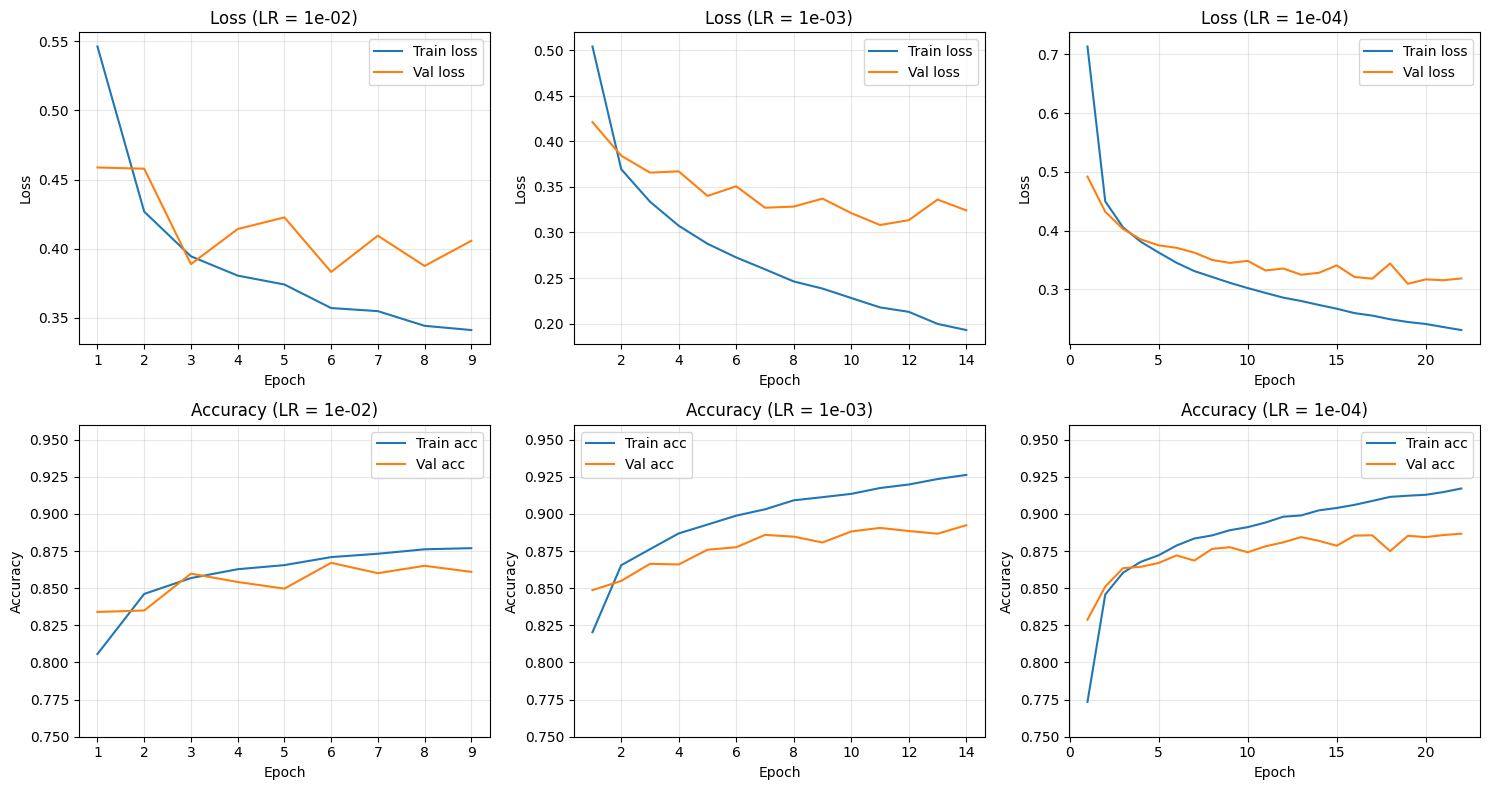

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (lr_label, hist) in enumerate(histories_b2.items()):
    epochs_range = range(1, len(hist["loss"]) + 1)

    # Hàng 1: Loss curve
    axes[0, col].plot(epochs_range, hist["loss"], label="Train loss")
    axes[0, col].plot(epochs_range, hist["val_loss"], label="Val loss")
    axes[0, col].set_title(f"Loss (LR = {lr_label})")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("Loss")
    axes[0, col].legend()
    axes[0, col].grid(alpha=0.3)

    # Hàng 2: Accuracy curve
    axes[1, col].plot(epochs_range, hist["accuracy"], label="Train acc")
    axes[1, col].plot(epochs_range, hist["val_accuracy"], label="Val acc")
    axes[1, col].set_title(f"Accuracy (LR = {lr_label})")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Accuracy")
    axes[1, col].set_ylim(0.75, 0.96)
    axes[1, col].legend()
    axes[1, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
batch_sizes = [32, 128, 512]

results_b3 = []
histories_b3 = {}

for bs in batch_sizes:
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # Tạo pipeline tf.data mới theo từng batch_size
    train_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(buffer_size=len(X_train), seed=SEED)
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    test_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    print(f"\n>>> Đang huấn luyện với batch_size = {bs} ...")
    start_time = time.perf_counter()
    history = model.fit(
        train_ds_bs,
        validation_data=val_ds_bs,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.perf_counter() - start_time

    n_epochs = len(history.history["loss"])
    best_idx = int(np.argmin(history.history["val_loss"]))
    best_epoch = best_idx + 1
    best_val_loss = history.history["val_loss"][best_idx]
    best_val_acc = history.history["val_accuracy"][best_idx]
    test_loss, test_acc = model.evaluate(test_ds_bs, verbose=0)

    histories_b3[bs] = history.history
    results_b3.append({
        "Batch size": bs,
        "Steps/epoch": int(np.ceil(len(X_train) / bs)),
        "Epochs chạy": n_epochs,
        "Best epoch": best_epoch,
        "Train time (s)": round(train_time, 2),
        "Time/epoch (s)": round(train_time / n_epochs, 2),
        "Val loss": round(best_val_loss, 4),
        "Val accuracy": round(best_val_acc, 4),
        "Test accuracy": round(test_acc, 4)
    })

df_b3 = pd.DataFrame(results_b3)
print("\n=== BẢNG SO SÁNH BÀI 3: THỬ BATCH SIZE ===")
print(df_b3.to_string(index=False, justify="left"))


>>> Đang huấn luyện với batch_size = 32 ...

>>> Đang huấn luyện với batch_size = 128 ...

>>> Đang huấn luyện với batch_size = 512 ...

=== BẢNG SO SÁNH BÀI 3: THỬ BATCH SIZE ===
 Batch size  Steps/epoch  Epochs chạy  Best epoch  Train time (s)  Time/epoch (s)  Val loss  Val accuracy  Test accuracy
 32         1563         12            9          58.41           4.87            0.3171    0.8847        0.8817        
128          391         12            9          19.04           1.59            0.3189    0.8875        0.8820        
512           98         20           17          16.10           0.81            0.3080    0.8918        0.8852        


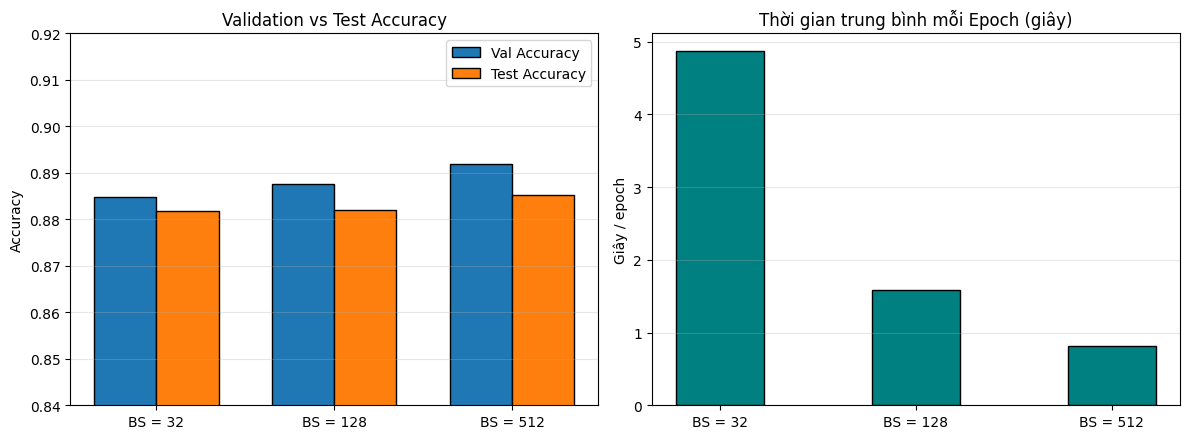

In [7]:
labels = [f"BS = {bs}" for bs in batch_sizes]
x = np.arange(len(labels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: Validation vs Test Accuracy
axes[0].bar(x - width/2, df_b3["Val accuracy"], width, label="Val Accuracy", edgecolor="black")
axes[0].bar(x + width/2, df_b3["Test accuracy"], width, label="Test Accuracy", edgecolor="black")
axes[0].set_title("Validation vs Test Accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.84, 0.92)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Biểu đồ 2: Thời gian mỗi epoch (giây)
axes[1].bar(x, df_b3["Time/epoch (s)"], width=0.45, color="teal", edgecolor="black")
axes[1].set_title("Thời gian trung bình mỗi Epoch (giây)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Giây / epoch")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
def build_mlp_dropout(dropout_rate=0.0):
    layers = [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
    ]
    if dropout_rate > 0:
        layers.append(tf.keras.layers.Dropout(dropout_rate))
    layers.append(tf.keras.layers.Dense(128, activation="relu"))
    if dropout_rate > 0:
        layers.append(tf.keras.layers.Dropout(dropout_rate))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    return tf.keras.Sequential(layers)

configs_b4 = {
    "Baseline (No Dropout)": 0.0,
    "MLP + Dropout(0.3)": 0.3
}

results_b4 = []
histories_b4 = {}

for name, rate in configs_b4.items():
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = build_mlp_dropout(dropout_rate=rate)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    print(f"\n>>> Đang huấn luyện: {name} ...")
    start_time = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.perf_counter() - start_time

    hist = history.history
    best_idx = int(np.argmin(hist["val_loss"]))
    best_epoch = best_idx + 1

    train_acc_best = hist["accuracy"][best_idx]
    val_acc_best = hist["val_accuracy"][best_idx]
    gap_best = train_acc_best - val_acc_best
    gap_last = hist["accuracy"][-1] - hist["val_accuracy"][-1]

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    histories_b4[name] = hist
    results_b4.append({
        "Mô hình": name,
        "Epochs chạy": len(hist["loss"]),
        "Best epoch": best_epoch,
        "Train time (s)": round(train_time, 2),
        "Train acc (best)": round(train_acc_best, 4),
        "Val acc (best)": round(val_acc_best, 4),
        "Gap best": round(gap_best, 4),
        "Gap cuối": round(gap_last, 4),
        "Val loss": round(hist["val_loss"][best_idx], 4),
        "Test accuracy": round(test_acc, 4)
    })

df_b4 = pd.DataFrame(results_b4)
print("\n=== BẢNG SO SÁNH BÀI 4: THÊM DROPOUT(0.3) ===")
print(df_b4.to_string(index=False, justify="left"))


>>> Đang huấn luyện: Baseline (No Dropout) ...

>>> Đang huấn luyện: MLP + Dropout(0.3) ...

=== BẢNG SO SÁNH BÀI 4: THÊM DROPOUT(0.3) ===
Mô hình                Epochs chạy  Best epoch  Train time (s)  Train acc (best)  Val acc (best)  Gap best  Gap cuối  Val loss  Test accuracy
Baseline (No Dropout) 10            7          28.04           0.9020            0.8865           0.0155   0.0318    0.3173    0.8792        
   MLP + Dropout(0.3) 15           12          39.66           0.8882            0.8898          -0.0016   0.0032    0.3073    0.8817        


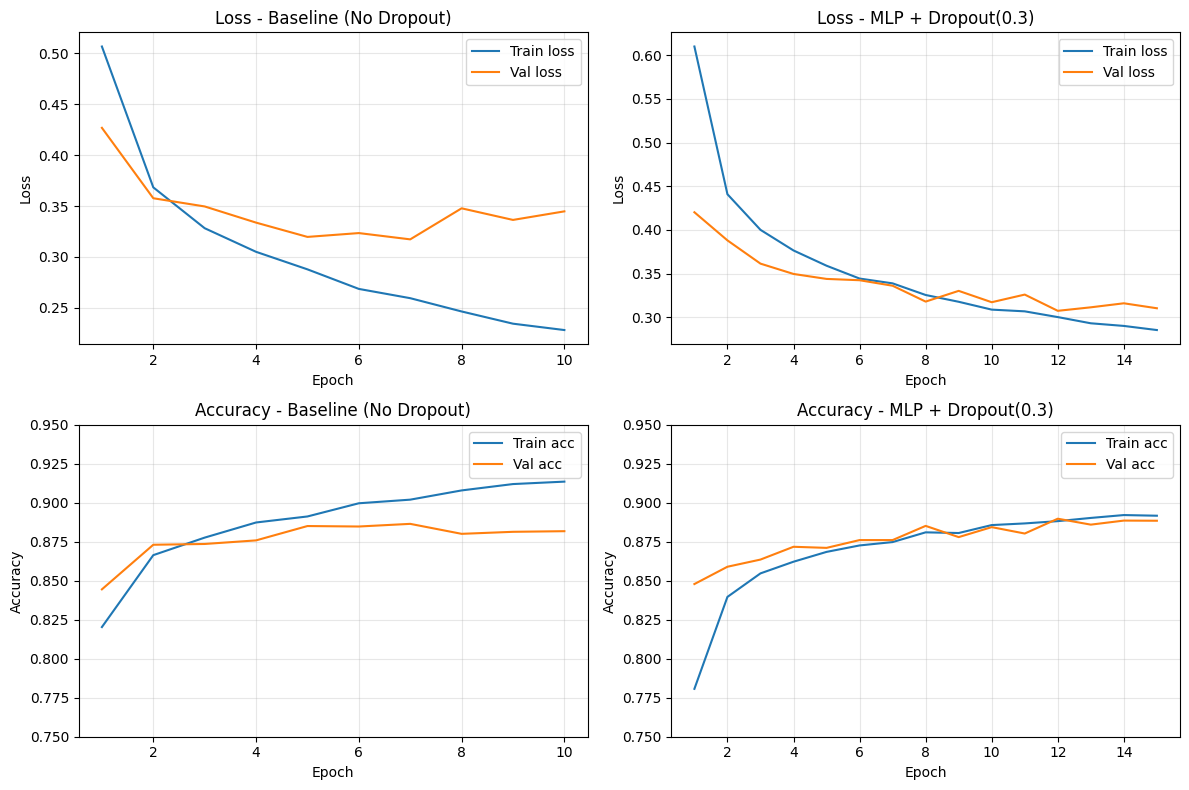

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, (name, hist) in enumerate(histories_b4.items()):
    epochs_range = range(1, len(hist["loss"]) + 1)

    # Hàng 1: Loss curve
    axes[0, col].plot(epochs_range, hist["loss"], label="Train loss")
    axes[0, col].plot(epochs_range, hist["val_loss"], label="Val loss")
    axes[0, col].set_title(f"Loss - {name}")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("Loss")
    axes[0, col].legend()
    axes[0, col].grid(alpha=0.3)

    # Hàng 2: Accuracy curve
    axes[1, col].plot(epochs_range, hist["accuracy"], label="Train acc")
    axes[1, col].plot(epochs_range, hist["val_accuracy"], label="Val acc")
    axes[1, col].set_title(f"Accuracy - {name}")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Accuracy")
    axes[1, col].set_ylim(0.75, 0.95)
    axes[1, col].legend()
    axes[1, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
def build_mlp_l2(l2_lambda=0.0):
    reg = tf.keras.regularizers.l2(l2_lambda) if l2_lambda > 0 else None
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

l2_configs = {
    "Baseline (No L2)": 0.0,
    "L2 = 1e-4": 1e-4,
    "L2 = 1e-3": 1e-3,
    "L2 = 1e-2": 1e-2
}

results_b5 = []
histories_b5 = {}

for name, lam in l2_configs.items():
    tf.keras.backend.clear_session()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = build_mlp_l2(l2_lambda=lam)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    print(f"\n>>> Đang huấn luyện: {name} ...")
    start_time = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.perf_counter() - start_time

    hist = history.history
    best_idx = int(np.argmin(hist["val_loss"]))
    best_epoch = best_idx + 1

    train_acc_best = hist["accuracy"][best_idx]
    val_acc_best = hist["val_accuracy"][best_idx]
    gap_best = train_acc_best - val_acc_best
    gap_last = hist["accuracy"][-1] - hist["val_accuracy"][-1]

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    histories_b5[name] = hist
    results_b5.append({
        "Mô hình": name,
        "Epochs chạy": len(hist["loss"]),
        "Best epoch": best_epoch,
        "Train time (s)": round(train_time, 2),
        "Train acc (best)": round(train_acc_best, 4),
        "Val acc (best)": round(val_acc_best, 4),
        "Gap best": round(gap_best, 4),
        "Gap cuối": round(gap_last, 4),
        "Val loss": round(hist["val_loss"][best_idx], 4),
        "Test accuracy": round(test_acc, 4)
    })

df_b5 = pd.DataFrame(results_b5)
print("\n=== BẢNG SO SÁNH BÀI 5: THÊM L2 REGULARIZATION ===")
print(df_b5.to_string(index=False, justify="left"))


>>> Đang huấn luyện: Baseline (No L2) ...

>>> Đang huấn luyện: L2 = 1e-4 ...

>>> Đang huấn luyện: L2 = 1e-3 ...

>>> Đang huấn luyện: L2 = 1e-2 ...

=== BẢNG SO SÁNH BÀI 5: THÊM L2 REGULARIZATION ===
Mô hình           Epochs chạy  Best epoch  Train time (s)  Train acc (best)  Val acc (best)  Gap best  Gap cuối  Val loss  Test accuracy
Baseline (No L2) 11            8          30.90           0.9086            0.8878           0.0208   0.0284    0.3147    0.8814        
       L2 = 1e-4  9            6          27.18           0.8919            0.8872           0.0047   0.0235    0.3727    0.8746        
       L2 = 1e-3 13           10          32.83           0.8817            0.8750           0.0067   0.0119    0.4236    0.8698        
       L2 = 1e-2 13           10          33.52           0.8456            0.8482          -0.0026   0.0059    0.5359    0.8441        


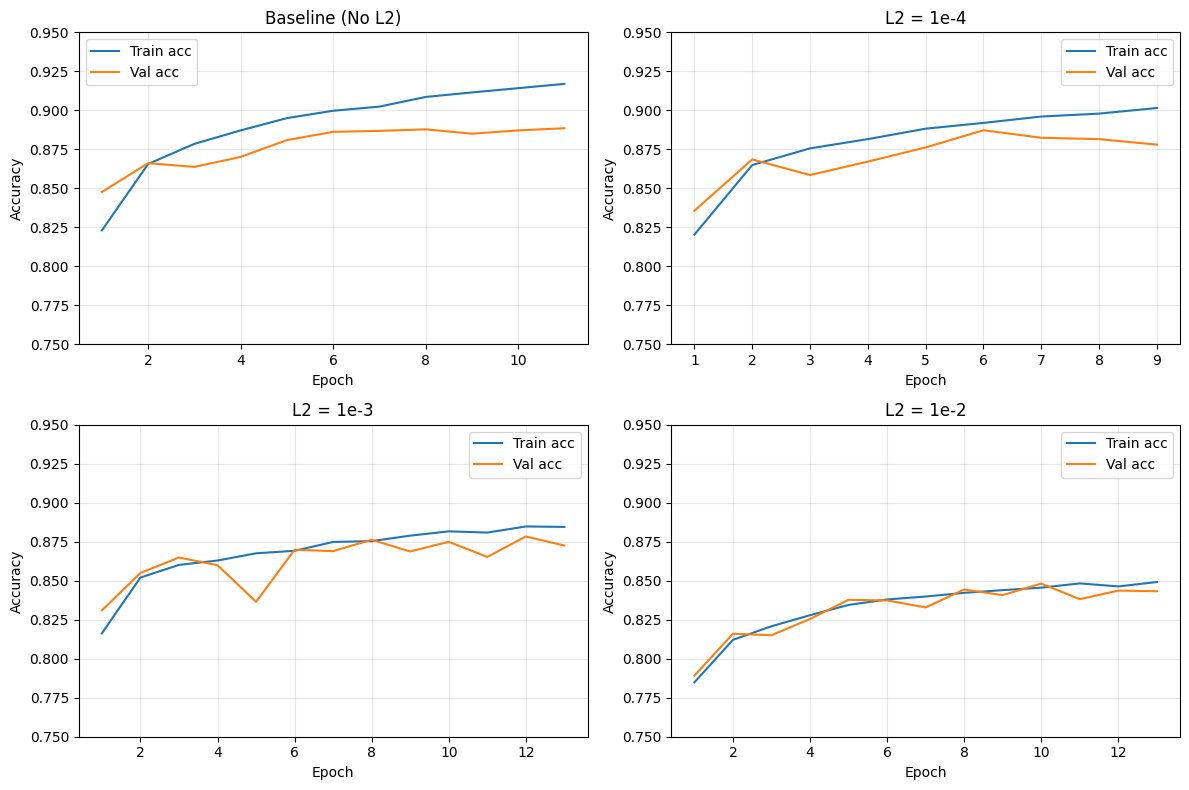

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for idx, (name, hist) in enumerate(histories_b5.items()):
    epochs_range = range(1, len(hist["loss"]) + 1)
    axes[idx].plot(epochs_range, hist["accuracy"], label="Train acc")
    axes[idx].plot(epochs_range, hist["val_accuracy"], label="Val acc")
    axes[idx].set_title(name)
    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("Accuracy")
    axes[idx].set_ylim(0.75, 0.95)
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
tf.keras.backend.clear_session()
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

model_b6 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_b6.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_b6 = model_b6.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
    verbose=0
)

best_epoch_b6 = int(np.argmin(history_b6.history["val_loss"])) + 1
test_loss_b6, test_acc_b6 = model_b6.evaluate(test_ds, verbose=0)
print(f"Best epoch: {best_epoch_b6} | Test loss: {test_loss_b6:.4f} | Test accuracy: {test_acc_b6:.4f}")

# Dự đoán xác suất trên tập Test
y_prob = model_b6.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
confidences = np.max(y_prob, axis=1)

# Lọc các mẫu dự đoán sai và sắp xếp theo confidence giảm dần
wrong_indices = np.where(y_pred != y_test)[0]
sorted_wrong = wrong_indices[np.argsort(confidences[wrong_indices])[::-1]]
top20_idx = sorted_wrong[:20]

# Lập bảng 20 mẫu sai có confidence cao nhất
rows_top20 = []
for rank, idx in enumerate(top20_idx, start=1):
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    rows_top20.append({
        "Top": rank,
        "Index": int(idx),
        "Nhãn thật": class_names[true_lbl],
        "Dự đoán": class_names[pred_lbl],
        "Conf (Dự đoán)": round(float(confidences[idx]), 4),
        "Prob (Nhãn thật)": round(float(y_prob[idx, true_lbl]), 4)
    })

df_top20 = pd.DataFrame(rows_top20)
print(f"\nTổng số mẫu dự đoán sai: {len(wrong_indices)} / {len(y_test)}")
print("\n=== TOP 20 MẪU DỰ ĐOÁN SAI CÓ CONFIDENCE CAO NHẤT ===")
print(df_top20.to_string(index=False, justify="left"))

# Thống kê top 5 cặp lớp bị nhầm nhiều nhất trên toàn tập Test
cm = confusion_matrix(y_test, y_pred)
pair_errors = []
for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        total_err = cm[i, j] + cm[j, i]
        if total_err > 0:
            pair_errors.append({
                "Cặp lớp": f"{class_names[i]} <-> {class_names[j]}",
                "Tổng nhầm": int(total_err),
                "A -> B": int(cm[i, j]),
                "B -> A": int(cm[j, i])
            })

df_pairs = pd.DataFrame(pair_errors).sort_values("Tổng nhầm", ascending=False).head(5)
print("\n=== TOP 5 CẶP LỚP BỊ NHẦM NHIỀU NHẤT (TOÀN TẬP TEST) ===")
print(df_pairs.to_string(index=False, justify="left"))

Best epoch: 8 | Test loss: 0.3399 | Test accuracy: 0.8763

Tổng số mẫu dự đoán sai: 1237 / 10000

=== TOP 20 MẪU DỰ ĐOÁN SAI CÓ CONFIDENCE CAO NHẤT ===
 Top  Index Nhãn thật   Dự đoán      Conf (Dự đoán)  Prob (Nhãn thật)
 1   5235        Sandal         Bag 1.0000          0.0000           
 2   2599   T-shirt/top         Bag 0.9998          0.0001           
 3   4040        Sandal     Sneaker 0.9997          0.0003           
 4   8557    Ankle boot      Sandal 0.9997          0.0003           
 5   3531   T-shirt/top       Dress 0.9997          0.0000           
 6   5946    Ankle boot      Sandal 0.9995          0.0005           
 7   7936    Ankle boot     Sneaker 0.9992          0.0008           
 8   6565           Bag     Sneaker 0.9988          0.0011           
 9   8074       Trouser       Dress 0.9983          0.0010           
10   2022       Sneaker  Ankle boot 0.9982          0.0017           
11   9059         Dress     Trouser 0.9975          0.0010           
12   285

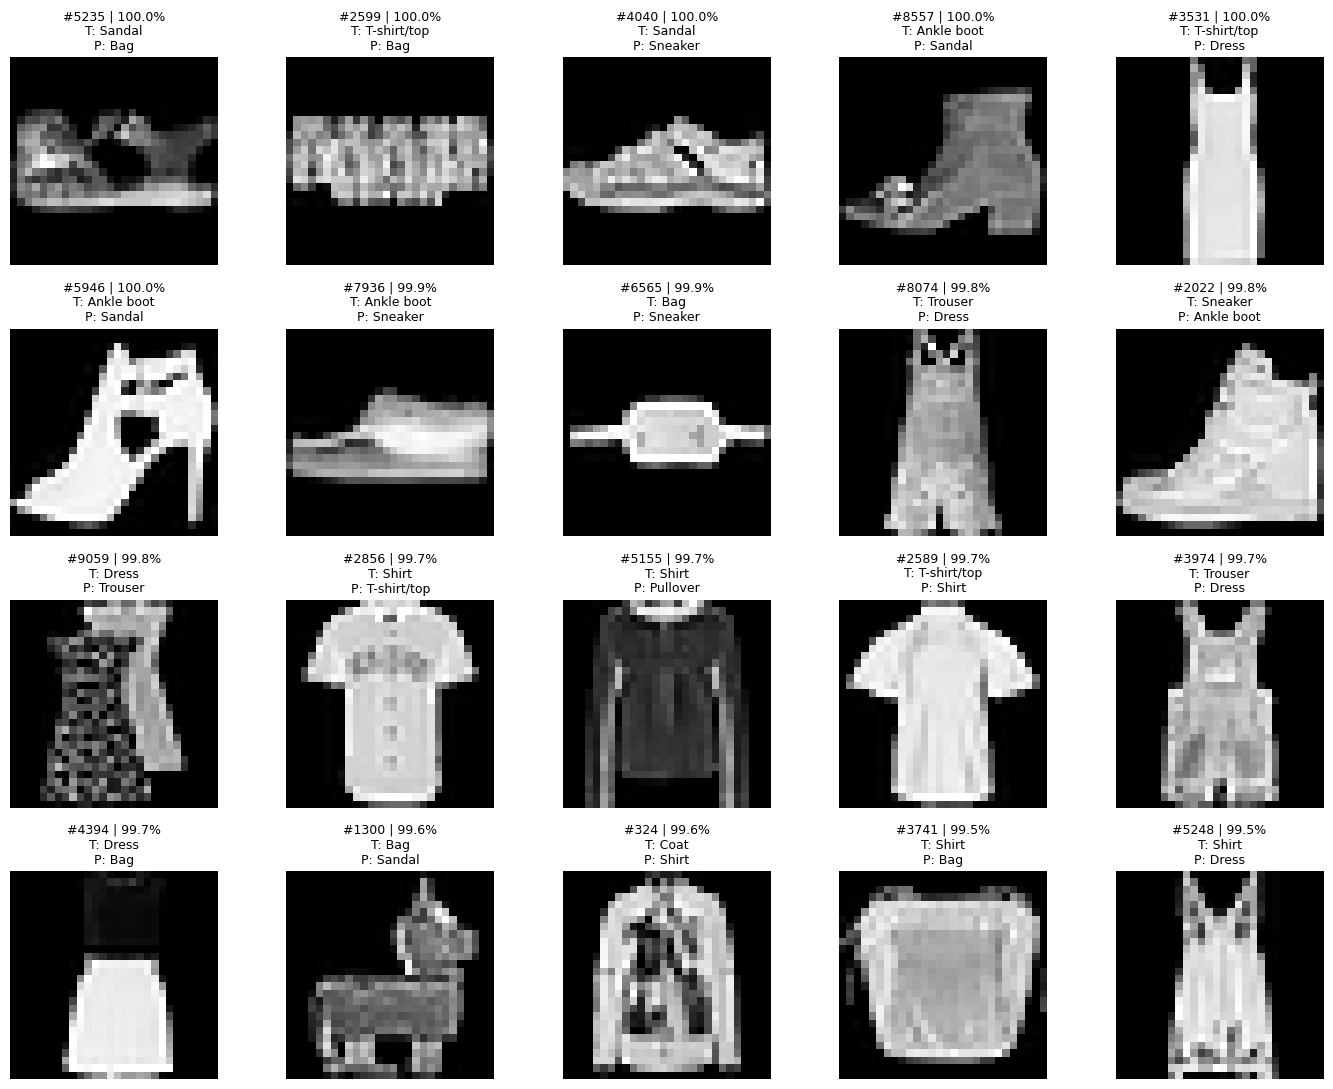

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for ax, idx in zip(axes.ravel(), top20_idx):
    true_name = class_names[y_test[idx]]
    pred_name = class_names[y_pred[idx]]
    conf = confidences[idx] * 100
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"#{idx} | {conf:.1f}%\nT: {true_name}\nP: {pred_name}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()